# MicroGrad: from scalar derivatives to a classifier
**Yousef Mohamed Mahmoud Helmy Ismail · 20P7954**  
Ain Shams University, Faculty of Engineering · CSE485-CSE488: Deep Learning  
Assignment 1 · 3 November 2026

This notebook builds all training derivatives with `src.engine.Value` and trains
`src.nn.MLP`. NumPy generates data and supports plotting; it provides no autograd.
Run every cell in order. No dataset download or saved checkpoint is required.
The final 80 test samples are reserved before training and do not affect updates.


In [1]:
import sys, random, math, json, platform, time, gc
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/engine.py').is_file(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from src.engine import Value
from src.nn import MLP
from scripts.verify import run_checks
SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
FIG = ROOT / 'report/figures'
ART = ROOT / 'artifacts'
FIG.mkdir(parents=True, exist_ok=True)
ART.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
def save_figure(fig, name):
    fig.savefig(FIG / (name+'.png'), dpi=300, bbox_inches='tight')
    fig.savefig(FIG / (name+'.pdf'), bbox_inches='tight')
print('Python', platform.python_version(), '| NumPy', np.__version__)
print('Seed:', SEED, '| engine:', Value.__module__)

Python 3.12.14 | NumPy 2.5.4
Seed: 42 | engine: src.engine


## 1. Verify the engine before training
For each scalar operation, the local backward closure adds an upstream derivative
times its local partial derivative. A visited set makes each graph node execute
once, while the closure still adds both operand contributions when they refer to
the same `Value`. Central finite differences independently check 60 partials.


In [2]:
verification = run_checks()
print(json.dumps(verification, indent=2))
a = Value(3.0, label='a')
c = a+a
c.label = 'c = a+a'
d = c*a
d.label = 'd = c*a'
d.backward()
assert a.grad == 12.0
topo = d._get_topo()
assert len(topo) == 3
print('Topological order:', [node.label for node in topo])
print('Derivative of (a+a)*a at a=3:', a.grad)

{
  "diamond_checks": 3,
  "composite_points": 30,
  "partial_derivatives_checked": 60,
  "step": 1e-06,
  "max_absolute_error": 2.985505176411607e-10,
  "status": "PASS"
}
Topological order: ['a', 'c = a+a', 'd = c*a']
Derivative of (a+a)*a at a=3: 12.0


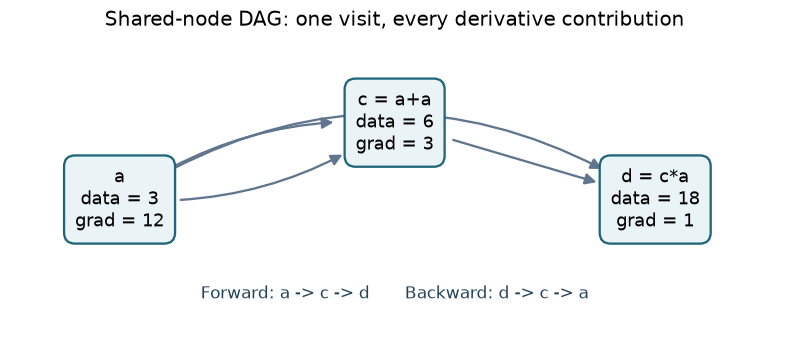

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
positions = {a:(0.12,.5), c:(.5,.78), d:(.86,.5)}
for src,dst,rad,label in [(a,c,.18,'left operand'), (a,c,-.18,'right operand'),
                           (c,d,0,''), (a,d,-.32,'direct path')]:
    ax.add_patch(FancyArrowPatch(positions[src], positions[dst],
        connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>',
        mutation_scale=15, color='#60758e', linewidth=1.5,
        shrinkA=40, shrinkB=40))
for node,(x,y) in positions.items():
    text = f'{node.label}\ndata = {node.data:g}\ngrad = {node.grad:g}'
    ax.text(x,y,text,ha='center',va='center',fontsize=12,
            bbox=dict(boxstyle='round,pad=.6',fc='#eaf4f7',ec='#20667a',lw=1.5))
ax.text(.5,.14,'Forward: a -> c -> d       Backward: d -> c -> a',
        ha='center',fontsize=11,color='#244257')
ax.set(xlim=(-.03,1.03),ylim=(-.03,1.05))
ax.axis('off')
ax.set_title('Shared-node DAG: one visit, every derivative contribution',pad=15)
save_figure(fig,'computational_graph')
plt.show()

## 2. Generate noisy two-moons data and reserve the test set
The first arc is `(cos(t), sin(t))`; the second is
`(1-cos(t), 0.5-sin(t))`, with independent Gaussian noise of standard
deviation 0.12. Each class has 120 samples. A seeded permutation reserves
40 from each class for testing and uses 80 from each class for training.
No normalization is learned from the test samples.


In [4]:
t = np.linspace(0, np.pi, 120)
X = np.vstack([np.column_stack([np.cos(t),np.sin(t)]),
               np.column_stack([1-np.cos(t),.5-np.sin(t)])])
X += rng.normal(0,.12,X.shape)
y = np.r_[-np.ones(120),np.ones(120)]
train_idx, test_idx = [], []
for indices in [np.arange(120),np.arange(120,240)]:
    shuffled = rng.permutation(indices)
    train_idx.extend(shuffled[:80])
    test_idx.extend(shuffled[80:])
train_idx, test_idx = np.array(train_idx), np.array(test_idx)
X_train, y_train = X[train_idx].tolist(), y[train_idx].tolist()
X_test, y_test = X[test_idx].tolist(), y[test_idx].tolist()
assert not set(train_idx).intersection(test_idx)
np.savez(ART/'dataset.npz', X=X,y=y,train_idx=train_idx,test_idx=test_idx)
print(f'Training: {len(train_idx)} | held-out test: {len(test_idx)} | features: 2')

Training: 160 | held-out test: 80 | features: 2


## 3. Define the model and objective
The network has widths **2 -> 8 -> 8 -> 1**, `tanh` at every neuron, and
105 trainable parameters. Labels are -1 and +1; score zero is the decision
threshold. The objective is mean squared error plus an L2 penalty on weights:

$$L(\theta)=\frac{1}{N}\sum_i(f_\theta(x_i)-y_i)^2
             +\frac{10^{-4}}{|W|}\sum_{w\in W}w^2.$$

Full-batch gradient descent uses $\eta_e=0.12(1-0.75e/300)$ for
300 updates. Every update builds a fresh graph, clears parameter gradients,
backpropagates once, and updates parameters after differentiation.
Metrics are measured at each recorded parameter state, including state 0.


In [5]:
model = MLP(2, [8,8,1])
params = model.parameters()
weights = [w for layer in model.layers for neuron in layer.neurons for w in neuron.w]
assert len(params) == 105
L2 = 1e-4
EPOCHS = 300
def scalar_score(row):
    # Graph-free scalar inference for logging and dense plotting only.
    current = row
    for layer in model.layers:
        current = [math.tanh(sum(w.data*x for w,x in zip(n.w,current))+n.b.data)
                   for n in layer.neurons]
    return current[0]
def metrics(rows, labels):
    scores = [scalar_score(row) for row in rows]
    mse = sum((score-label)**2 for score,label in zip(scores,labels))/len(labels)
    accuracy = sum((score>=0)==(label>0) for score,label in zip(scores,labels))/len(labels)
    return mse, accuracy
def record(epoch):
    train_mse, train_acc = metrics(X_train,y_train)
    test_mse, test_acc = metrics(X_test,y_test)
    reg = L2*sum(w.data**2 for w in weights)/len(weights)
    return dict(epoch=epoch,objective=train_mse+reg,train_mse=train_mse,
                test_mse=test_mse,train_accuracy=train_acc,test_accuracy=test_acc)
print('Parameters:', len(params), '| regularized weights:', len(weights))

Parameters: 105 | regularized weights: 88


In [6]:
history = [record(0)]
start = time.perf_counter()
for epoch in range(EPOCHS):
    predictions = [model(row) for row in X_train]
    data_loss = sum((prediction-label)**2 for prediction,label in zip(predictions,y_train))/len(y_train)
    penalty = (L2/len(weights))*sum(w*w for w in weights)
    loss = data_loss+penalty
    assert math.isfinite(loss.data)
    model.zero_grad()
    loss.backward()
    rate = .12*(1-.75*epoch/EPOCHS)
    for p in params:
        p.data -= rate*p.grad
    history.append(record(epoch+1))
    if (epoch+1)%50 == 0:
        last = history[-1]
        print(f"Epoch {epoch+1:3d} | objective {last['objective']:.5f} | "
              f"train {last['train_accuracy']:.1%} | test {last['test_accuracy']:.1%}")
    del predictions, data_loss, penalty, loss
    if epoch%10 == 0:
        gc.collect()
elapsed = time.perf_counter()-start
for row in X_train+X_test:
    assert math.isclose(model(row).data,scalar_score(row),rel_tol=1e-12,abs_tol=1e-12)
summary = dict(seed=SEED,epochs=EPOCHS,parameters=len(params),train_samples=len(X_train),
    test_samples=len(X_test),initial=history[0],final=history[-1],training_seconds=elapsed,
    verification=verification)
(ART/'metrics.json').write_text(json.dumps(summary,indent=2))
(ART/'history.json').write_text(json.dumps(history,indent=2))
(ART/'parameters.json').write_text(json.dumps([p.data for p in params],indent=2))
print(json.dumps(summary,indent=2))
assert history[-1]['objective'] < history[0]['objective']
assert history[-1]['test_accuracy'] >= .90

Epoch  50 | objective 0.17386 | train 95.6% | test 96.2%


Epoch 100 | objective 0.09802 | train 98.8% | test 97.5%


Epoch 150 | objective 0.06211 | train 99.4% | test 97.5%


Epoch 200 | objective 0.04550 | train 99.4% | test 97.5%


Epoch 250 | objective 0.03702 | train 99.4% | test 97.5%


Epoch 300 | objective 0.03246 | train 99.4% | test 97.5%


{
  "seed": 42,
  "epochs": 300,
  "parameters": 105,
  "train_samples": 160,
  "test_samples": 80,
  "initial": {
    "epoch": 0,
    "objective": 0.8036536133446845,
    "train_mse": 0.8036167392195146,
    "test_mse": 0.9804888323735979,
    "train_accuracy": 0.7375,
    "test_accuracy": 0.6375
  },
  "final": {
    "epoch": 300,
    "objective": 0.03246300461069391,
    "train_mse": 0.03240937121475131,
    "test_mse": 0.052757052652109435,
    "train_accuracy": 0.99375,
    "test_accuracy": 0.975
  },
  "training_seconds": 149.82142190006562,
  "verification": {
    "diamond_checks": 3,
    "composite_points": 30,
    "partial_derivatives_checked": 60,
    "step": 1e-06,
    "max_absolute_error": 2.985505176411607e-10,
    "status": "PASS"
  }
}


## 4. Inspect optimization and held-out performance
The test curves are diagnostics only: no early stopping, tuning, or gradient
updates use the test set. MSE below is the data term; the optimization objective
additionally includes the small weight penalty.


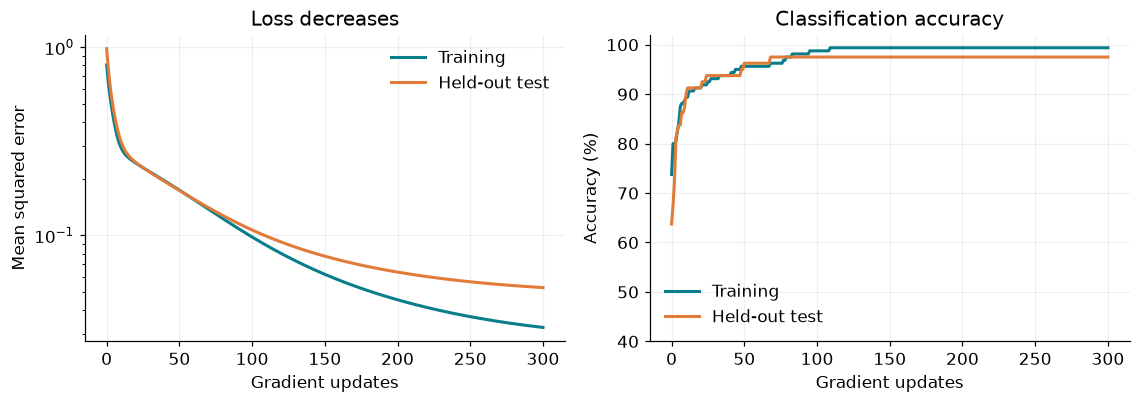

In [7]:
epochs = [row['epoch'] for row in history]
fig, axes = plt.subplots(1,2,figsize=(10.5,3.8))
for key,label,color in [('train_mse','Training','#087e8b'),('test_mse','Held-out test','#e07b39')]:
    axes[0].plot(epochs,[r[key] for r in history],label=label,color=color,lw=2)
axes[0].set(xlabel='Gradient updates',ylabel='Mean squared error',yscale='log',title='Loss decreases')
for key,label,color in [('train_accuracy','Training','#087e8b'),('test_accuracy','Held-out test','#e07b39')]:
    axes[1].plot(epochs,[100*r[key] for r in history],label=label,color=color,lw=2)
axes[1].set(xlabel='Gradient updates',ylabel='Accuracy (%)',ylim=(40,102),title='Classification accuracy')
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=.18)
fig.tight_layout()
save_figure(fig,'training_curves')
plt.show()

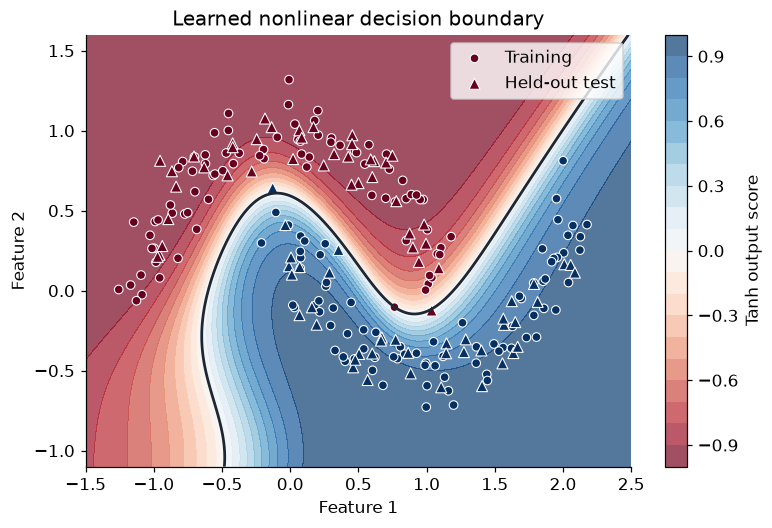

In [8]:
xx,yy = np.meshgrid(np.linspace(-1.5,2.5,180),np.linspace(-1.1,1.6,140))
scores = np.array([scalar_score(row) for row in zip(xx.ravel(),yy.ravel())]).reshape(xx.shape)
fig,ax = plt.subplots(figsize=(8,5.1))
contour = ax.contourf(xx,yy,scores,levels=np.linspace(-1,1,21),cmap='RdBu',alpha=.7)
ax.contour(xx,yy,scores,levels=[0],colors='#1b2735',linewidths=1.8)
for label,mark,indices in [('Training','o',train_idx),('Held-out test','^',test_idx)]:
    ax.scatter(X[indices,0],X[indices,1],c=y[indices],cmap='RdBu',vmin=-1,vmax=1,
               marker=mark,s=32 if mark=='o' else 52,edgecolors='white',linewidths=.7,label=label)
fig.colorbar(contour,ax=ax,label='Tanh output score')
ax.set(xlabel='Feature 1',ylabel='Feature 2',title='Learned nonlinear decision boundary')
ax.legend(frameon=True,loc='upper right')
save_figure(fig,'decision_boundary')
plt.show()

## 5. Interpretation and limits
The curved zero contour shows that a composition of scalar neurons can learn a
nonlinear classifier. A held-out split gives a more useful check than training
accuracy alone, although this is one small synthetic dataset and one seed.
The implementation prioritizes readable chain-rule mechanics: it has no tensors,
GPU execution, batching primitive, retained-graph management, or automatic
gradient reset. Recursive DFS is limited by Python's recursion depth on very
deep chains. `exp` follows Python overflow behavior and real powers require a
valid real domain. Dense figures use a graph-free scalar evaluation of the same
learned weights, checked against `MLP.__call__` on every dataset sample.

**Reproduction:** from the repository root, install `requirements.txt`, then run
`python -m nbconvert --to notebook --execute --inplace notebooks/demo.ipynb`.
Figures are saved as 300 DPI PNGs and vector PDFs. Metrics, dataset splits,
training history, and learned parameters are exported under `artifacts/`.
